## Deep Hedging Implementation: derived from "Deep Hedging" - Oxford, JPMorgan Chase (2018)

A framework for hedging a derivatives portfolio under market frictions (mainly transaction costs) using deep reinforcement learning methods.
Authors: Akshu Enaganti, Leandro Sanchez-Betancourt

### Step 1: Heston Model Simulation

The Heston model is a continuous time stochastic volatility model dependent on 2 stochastic differential equations (one for stock price, and one for variance). 

Stock Price Process: $$dS^1_t = \sqrt{V_t} S^1_t dB_t$$

Variance Process (CIR): $$dV_t = \kappa(\theta - V_t)dt + \sigma\sqrt{V_t}dW_t$$

where $B_t$, $W_t$ are Brownian motions with correlation $\rho$, i.e. $d\langle B, W \rangle_t = \rho \, dt$.


For the scope of this implementation, the Heston model is approximated in a discrete-time setting, where the following equations now hold. 

Stock Price (log-Euler): $$S^1_{k+1} = S^1_k \cdot \exp\left(-\frac{1}{2}V_k \Delta t + \sqrt{V_k \Delta t} \, W^1_k\right)$$

Variance Process (Euler): $$V_{k+1} = \max\left(V_k + \kappa(\theta - V_k)\Delta t + \sigma\sqrt{V_k \Delta t} \, W^2_k, \, 0\right)$$

where $W^1_k, W^2_k$ are correlated standard normals.

Aside from the stock itself, the other tradeable instrument is a variance swap, or a contract whose price reflects total expected realized variance over [0, T], given a current variance $V_t$. The equation for the variance swap price is shown below.

Variance Swap Price (equation 5.4): $$S^2_t = \int_0^t V_s \, ds + L(t, V_t),$$ $$L(t, v) = \frac{v - \theta}{\kappa}\left(1 - e^{-\kappa(T-t)}\right) + \theta(T-t)$$

Simulating the Heston model gives a market model to exercise and validate trading strategies within.

In [11]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

In [12]:
import numpy as np

# Data Generation (Heston Model Simulator)
def Heston(N, n=30, S0=100, v0=0.04, kappa=1.0, theta=0.04, 
                    sigma=2.0, rho=-0.7, T=30/365):
    """
    [in]: num. paths (N), num. timesteps (n), init. stock price (S0),
            init. var. (v0), mean reversion speed of var. (kappa),
            long-run mean var. (theta), volatility of volatility (sigma),
            corr. between stock price and var. moves (rho), 
            time horizon in years (T)
    [out]: stock (S1), var. swap (S2), var. process (V)
    
    Simulate N paths of Heston model over n timesteps.
    """

    dt = T/n
    
    # Shape of output sequences: N paths, n+1 timesteps
    S1 = np.zeros((N, n+1))
    S2 = np.zeros((N, n+1))
    V = np.zeros((N, n+1))
    
    # Initial values on each path: S0, v0
    S1[:, 0], V[:, 0] = S0, v0

    for k in range(n):
        # 2 std. norm. w/correlation
        Z1, Z2 = np.random.normal(0, 1, N), np.random.normal(0, 1, N)
        W1 = Z1
        W2 = rho * Z1 + np.sqrt(1 - (rho**2)) * Z2

        # Stock price update (formula: log-Euler )
        S1[:, k+1] = S1[:, k] * np.exp(-0.5 * V[:, k] * dt + np.sqrt(np.maximum(V[:, k], 0) * dt) * W1)

        # Variance update (formula: Euler discretization of dVt equation)
        V[:, k+1] = np.maximum((V[:, k] + kappa * (theta - V[:, k]) * dt + 
                                sigma * np.sqrt(np.maximum(V[:, k], 0)) * np.sqrt(dt) * W2), 0)

    # Variance swap price (equation 5.4: S2t = integral from 0 to t (Vs ds) + L(t, Vt))
        # L(t, v): (v-theta)/kappa * (1-e^(-kappa(T-t))) + theta*(T-t)

    t_grid = np.linspace(0, T, n+1) # 0/365 -> 30/365

    for k in range(n+1):
        t = t_grid[k]
        L = ((V[:, k] - theta) / kappa) * (1 - np.exp(-kappa * (T - t))) + theta * (T - t)

        # Approximation of integral: sum * dt
        re_var = np.sum(V[:, :k+1], axis=1) * dt if k > 0 else 0

        # Variance swap: sum of past realized var., expected realized var. 
        S2[:, k] = re_var + L

    return S1, S2, V

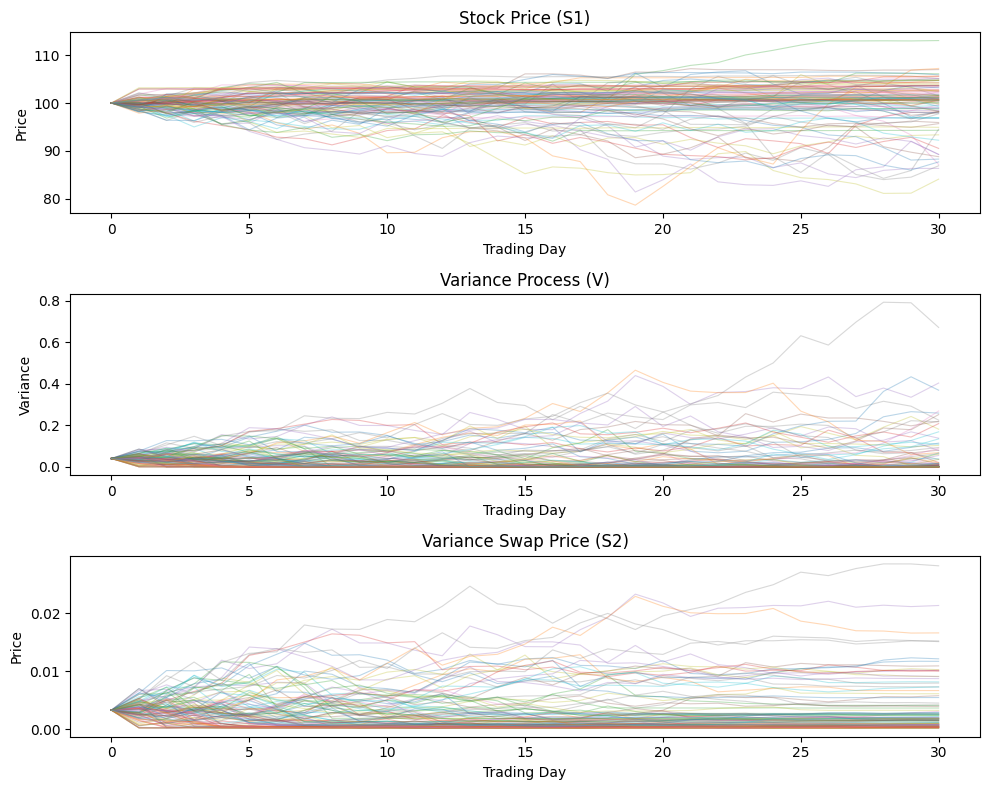

In [13]:
# Added visuals for Heston model process
import matplotlib.pyplot as plt

S1, S2, V = Heston(N=1000)

fig, axes = plt.subplots(3, 1, figsize=(10, 8))

# 100 sample paths for each
axes[0].plot(S1[:100].T, alpha=0.3, linewidth=0.8)
axes[0].set_title('Stock Price (S1)')
axes[0].set_xlabel('Trading Day')
axes[0].set_ylabel('Price')

axes[1].plot(V[:100].T, alpha=0.3, linewidth=0.8)
axes[1].set_title('Variance Process (V)')
axes[1].set_xlabel('Trading Day')
axes[1].set_ylabel('Variance')

axes[2].plot(S2[:100].T, alpha=0.3, linewidth=0.8)
axes[2].set_title('Variance Swap Price (S2)')
axes[2].set_xlabel('Trading Day')
axes[2].set_ylabel('Price')

plt.tight_layout()
plt.show()

### Step 2: Recurrent Neural Netowrk 

In markets with friction, the optimal hedging strategy $\delta^*$ is an unknown function from market state to optimal holdings, at each timestep. The goal of the neural networks is to approximate $\delta^*$, as analytically solving for it is implausible. From Hornik's 1991 work, any continuous function can be approximated by a sufficiently large neural network, arbitrarily well enough.

Each network, at each timestep $k$, takes in current market information and the previous position ($\delta_{k-1}$), outputting the new position. 
$$\delta_k = F^{\theta_k}(I_k, \delta_{k-1}),$$
$$I_k = (\log S^1_k, V_k)$$

Transaction costs are dependent upon the change in position, necessitating the inclusion of $\delta_{k-1}$ in the networks.
$$C_T(\delta) = \sum_{k=0}^{n} \varepsilon |\delta_k - \delta_{k-1}| \cdot S^i_k$$

$n = 30$ distinct networks are used, one per trading day; each network independently learns its parameters $\theta_k$, modeling the optimal strategy on day $k$ (which, naturally, differs from the optimal strategy on day $k+1$). These networks are chained together; the output $\delta_k$ of network $k$ feeds as input into network $k+1$, allowing gradients to flow back through time through training.

In [14]:
# Neural Network Trading Strategies
class tradingStrategy(nn.Module):
    """
    [in]: market state (size=d), prev. position (size=d)
    [out]: new position (size=d)
    
    Neural network for a single day's trading strategy. Num. hedging 
    instruments: d=2 (stock, variance swap). Two hidden layers of size 
    d+15. Activation via ReLU (ReLU(x) = max(0, x)), batch normalization 
    to normalize outputs of layer prior to activating.
    """
    def __init__(self, d=2):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(in_features=2*d, out_features=d+15), # input: market state, prev. pos. (2d); output: first hidden layer (d+15)
            nn.BatchNorm1d(num_features=d+15), 
            nn.ReLU(), 

            nn.Linear(in_features=d+15, out_features=d+15), # input: first hidden layer (d+15); output: second hidden layer (d+15)
            nn.BatchNorm1d(num_features=d+15),
            nn.ReLU(),

            nn.Linear(in_features=d+15, out_features=d) # input: second hidden layer (d+15); output: new pos. (d)
        )

    # Forward pass
    def forward(self, x):
        return self.net(x)

class Hedge(nn.Module):
    """
    [in]: trading timesteps (n=30), market state (size=d), prev. position (size=d)
    [out]: new position (size=d)
    
    Full model of n separate neural networks, one at each timestep. 
    Models optimal trading decision going forward, given market 
    state and curr. holdings. Semi-recurrent structure derived from 
    equation 4.1: delta_k = F^{theta_k}(I_k, delta_{k-1}).
    """
    def __init__(self, n=30, d=2):
        super().__init__()
        self.n = n
        self.d = d

        # ModuleList of n separate networks, indep. & distinct weights
        self.networks = nn.ModuleList(
            [tradingStrategy(d=d) for _ in range(n)]
        )

    def forward(self, S):
        """
        [in]: market paths S; shape: (B, n+1, d)
            S[:, k, 0] = stock price S1 at timestep k,
            S[:, k, 1] = var. swap price S2 at timestep k

        [out]: holdings deltas; shape: (B, n, d)
            deltas[:, k, :] = holdings at timestep k 

        Forward pass through all n timesteps/networks.
        """
        B = S.shape[0] # batch size

        # Initial pos.: 0 holdings 
        delta_prev = torch.zeros(B, self.d)

        deltas = []
        for k in range(self.n):
            # Concatenate log market state (stabilize), prev. pos.: shape (B, 2d)
            I_k = torch.log(S[:, k, :])
            x = torch.cat([I_k, delta_prev], dim=1) 

            delta_k = self.networks[k](x)

            deltas.append(delta_k)
            delta_prev = delta_k

        # Shape transform: list of n (B, d) tensors -> (B, n, d)
        return torch.stack(deltas, dim=1)

In [15]:
# Verify NN with dummy inputs 

model = Hedge(n=30, d=2)
S_test = torch.ones(256, 31, 2) * 100  
deltas = model(S_test)

print(f"target output shape: (256, 30, 2), real output shape: {deltas.shape}")
print(f"total parameters: {sum(p.numel() for p in model.parameters())}")

target output shape: (256, 30, 2), real output shape: torch.Size([256, 30, 2])
total parameters: 14850


### Step 3: Convex Risk Measures

Consider the terminal profit and loss (P&L) under market frictions (sum of gains/losses from trades, premium charged, call option payoff cost, and transaction costs).
$$PL_T(Z, p_0, \delta) = -Z + p_0 + (\delta \cdot S)_T - C_T(\delta)$$

Regardless of what strategy is used, the terminal P&L will be random (due to the derivative prices in trades), and this demands a measure of how desirable a distribution of outcomes is. A convex risk measure $\rho(X)$ is defined as the minimum amount of cash that must be injected into position $X$ to make it "acceptable" ($\rho(X) \leq 0$). The convex risk measure satisfies three properties:
- Monotone: if X is always a better position than Y, X must require less cash injection
- Convex: a portfolio that is half A, half B is not riskier than the average individual risk of A and B 
- Cash-invariant: adding $\$c$ in cash reduces risk by exactly $\$c$ 

In turn, this creates the optimization problem (and loss function) for the training procedure.
$$\pi(X) = \inf_{\delta \in H} \rho\left(X + (\delta \cdot S)_T - C_T(\delta)\right)$$

$\pi(X)$ then represents the minimum achievable risk given an asset position $X$. This acts as the loss function; the networks attempt to find a trading strategy minimizing risk. The indifference price, defined as $p(Z) = \pi(-Z) - \pi(0)$, is the extra risk incurred from selling Z (difference of min. risk faced when selling derivative/hedging and min. risk faced when trading optimally distinctly). $p(Z)$ is typically charged to the client as a premium to compensate for the risk. To verify this, consider the case where $C_T = 0$. Then, $PL = 0$ with the optimal trading strategy, giving $\pi(-Z) = p_0 + \pi(0)$ or $p(Z) = p_0$ (the standard frictionless market result).

Two different risk measures are used in this implementation, as detailed below.

- CVaR: represents the expected shortfall or tail risk; average loss over worst $\alpha\%$ of outcomes. A higher $\alpha$ means a more risk averse position, where $\alpha = 0.5$ recovers behaviour close to the model delta hedge.
$$\rho(X) = \frac{1}{1-\alpha} \int_0^{1-\alpha} \text{VaR}_\gamma(X) \, d\gamma$$

- Entropic: similar to exponential utility. A higher $\lambda$ means a more risk averse position; a nice result is that as $\lambda \rightarrow 0$, $\rho(X) \rightarrow -E[X]$, which is the pure expected value of the asset without considering risk.
$$\rho(X) = \frac{1}{\lambda} \log \mathbb{E}\left[e^{-\lambda X}\right]$$

In [ ]:
# Risk Measures
def CVaR(PL, alpha=0.5):
    """
    [in]: terminal P&L for batch (PL), risk aversion level (alpha)
    [out]: CVaR risk measure

    Compute CVaR, or average loss in worst (1-alpha)% of scenarios.
    Derived from equation 3.5 in paper.
    """
    losses = -PL
    VaR = torch.quantile(losses, alpha)
    return losses[losses >= VaR].mean()

def entropic(PL, lam=1.0):
    """
    [in]: terminal P&L for batch (PL), risk aversion parameter (lam)
    [out]: entropic risk measure 

    Compute entropic risk measure, or exponential utility. 
    Derived from equation 3.4 in paper.
    """
    return (1/lam) * torch.log(torch.mean(torch.exp(-lam * PL)))

def compute_PL()

### Step 4: Model Training

The training loop is where the model "learns" the art of approximating an optimal strategy, after which its results can be evaluated in the testing stage. The full training loop is described below.

1. Sample a batch of market paths from Heston model simulator
2. Run each path through the 30 networks, outputting holdings $\delta_k$ at each timestep
3. Compute terminal P&L for batch
4. Evaluate risk measure $\rho$ on distribution of P&L outcomes
5. Backpropagate to update network weights based on loss function (Adam optimizer)

As mentioned earlier, terminal P&L is defined as follows. 
$$PL_T(Z, p_0, \delta) = -Z + p_0 + (\delta \cdot S)_T - C_T(\delta)$$

The term $(\delta \cdot S)_T$ simply represents cumulative trading gains, broken down below.
$$(\delta \cdot S)_T = \sum_{k=0}^{n-1} \delta_k \cdot (S_{k+1} - S_k)$$

To model transaction costs, a proportional model is used, where transaction costs are a function of the change in position and asset price. 
$$C_T(\delta) = \sum_{k=0}^{n} \varepsilon \sum_{i=1}^{d} |\delta^i_k - \delta^i_{k-1}| \cdot S^i_k$$

The loss function is a chosen risk measure, evaluated on the terminal P&L distribution across batch. A learning rate of 0.005 and batch size of 256 are used as standard hyperparameters for neural network training. The parameters are updated via the Adam optimizer, which allows for an adaptive learning rate across different parameters and tracks a momentum that simplifies gradient descent with magnitude.

In [ ]:
# Training
def train(N=50000, n_epochs=200, batch_size=256, lr=0.005, 
          epsilon=0.0, risk_measure='cvar', alpha=0.5, lam=1.0,
          K=100, T=30/365, n=30):
    """
    [in]: num. paths (N), num. epochs (n_epochs), batch size (batch_size),
          learning rate (lr), transaction cost (epsilon), 
          risk measure (risk_measure), CVaR level (alpha),
          entropic parameter (lam), strike (K), time horizon (T),
          num. timesteps (n)
    [out]: indifference price p(Z), trained model 

    Full training loop for series of neural networks.
    """

    # Heston model simulation
    S1, S2, V = Heston(N=N, n=n, T=T)
    S1_t = torch.tensor(S1, dtype=torch.float32)
    S2_t = torch.tensor(S2, dtype=torch.float32)
    S = torch.stack([S1_t, S2_t], dim=2) # shape: (N, n+1, 2)

    # Derivative payoff: (S1_T - K)+ for std. Eur. call option
    Z = torch.tensor(np.maximum(S1[:, -1] - K, 0), dtype=torch.float32)

    model = Hedge(n=n, d=2)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Training loop
    losses = []
    for epoch in range(n_epochs):
        indexes = torch.randperm(N)[:batch_size] 
        S_batch = S[indexes]
        Z_batch = Z[indexes]
        
        # Forward pass: holdings at each timestep
        model.train()
        deltas = model(S_batch) 

        # Compute terminal P&L; set p0 to risk neutral price
        p0 = Z.mean().item()
        PL = compute_PL(S_batch, deltas, Z_batch, p0, epsilon)
        
        # Chosen risk measure for loss 
        if risk_measure == 'cvar':
            loss = CVaR(PL, alpha=alpha)
        else:
            loss = entropic(PL, lam=lam)

        # Backpropagate, update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if epoch % 10 == 0:
            print(f"epoch {epoch}/{n_epochs} | loss: {loss.item():.4f}")



    # compute indifference price p(Z) = pi(-Z) - pi(0)
        # run full N paths through model, compute CVaR on P&L
        # p(Z) = risk(PL with -Z) - risk(PL with X=0)

    


### Step 5: Results


In [ ]:
# Results 